# **Portfolio Forecast Demo: Intraday Sessions and Gaps**

What 0.4.0 changes for intraday data, on hourly bars of New York Stock Exchange (XNYS) stocks from Yahoo Finance. Each session is a run of *marks*: its open, then each bar's close. The overnight move into the open is a return of its own, a *gap*, and the simulators forecast gaps and bars separately.

1. Download a year of hourly bars.
2. Backtest a portfolio on them.
3. Look at the marks of one session, on their real labels.
4. Read the return classes and the warnings that flag irregular returns.
5. Compare gap and bar volatility.
6. Lay out future marks across a weekend and a half-day.
7. Forecast with regime-switching Monte Carlo, where `sim_length` counts sessions.
8. Collapse the history to session closes for a daily view.
9. Switch to continuous mode for a 24/7 asset.

The data window is relative to today, so the numbers in the outputs change from run to run. Each section links to the README rule it demonstrates.

## **Imports**

In [1]:
# The simulators, reports, fan chart and calendar tools, plus yfinance and the exchange calendars
import exchange_calendars as xc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

from portfolio_forecast.forecast import nonparametric_monte_carlo, regime_switching_monte_carlo
from portfolio_forecast.performance import performance_report, simulate_buy_and_hold, statistical_report
from portfolio_forecast.performance.metrics import calculate_class_volatility
from portfolio_forecast.plotting import plot_simulated_paths
from portfolio_forecast.utils import classify_returns, close_times, next_trading_dates, to_session_values

## **Downloading Hourly Bars**

Yahoo Finance serves hourly bars for the last 730 days; `period='1y'` asks for the last year, about 250 sessions. Short histories overfit, especially in a trending market, so train on at least a year. Each bar is labelled with its *start*: the session's bars start at 9:30, 10:30, ..., 15:30 New York time, and the last one lasts only half an hour, to the 16:00 close. Intraday backtests need the `Open` field, since each session's open is a mark ([no opens](../README.md#b15-no-opens)).

In [2]:
# A year of hourly bars for three stocks, regular hours only
tickers = ['AAPL', 'MSFT', 'JPM']
data = yf.download(tickers, period='1y', interval='1h', auto_adjust=True, progress=False)
data['Close'].tail(7)

Ticker,AAPL,JPM,MSFT
Datetime,,,
2026-10-09 09:30:00-04:00,333.084412,331.369904,531.708313
2026-10-09 10:30:00-04:00,334.820007,332.209991,533.690002
2026-10-09 11:30:00-04:00,334.640015,332.834991,534.750000
2026-10-09 12:30:00-04:00,335.049988,332.739990,533.979980
2026-10-09 13:30:00-04:00,336.198700,332.714996,534.640015
2026-10-09 14:30:00-04:00,336.869995,333.250000,535.669983
2026-10-09 15:30:00-04:00,336.630005,333.000000,535.080017


## **Backtesting the Hourly Portfolio**

`simulate_buy_and_hold` buys at the first bar's open and values the portfolio at every mark ([point in time](../README.md#b11-point-in-time), [purchase](../README.md#b2-purchase)). It returns a `BacktestResult` whose `classes` give the class of each return, which the simulators use. See [Concepts](../README.md#concepts) for marks and classes in brief.

In [3]:
# The portfolio's value at each session's open and each bar's close, starting at 1.0
weights = {'AAPL': 0.4, 'MSFT': 0.3, 'JPM': 0.3}
backtest = simulate_buy_and_hold(data, weights)
backtest.values.tail(9)

/var/folders/4k/9t00rt713w3fsg126syp21gc0000gn/T/ipykernel_44870/798259344.py:3: UserWarning: 1 session(s) have no bar at the open, first 2026-02-02 13:30:00-05:00: each open mark is the first available bar's open, labelled at its start, and the return into it is irregular
  backtest = simulate_buy_and_hold(data, weights)
/var/folders/4k/9t00rt713w3fsg126syp21gc0000gn/T/ipykernel_44870/798259344.py:3: UserWarning: 3 return(s) are irregular, first ending 2025-12-01 09:30:00-05:00: a held symbol is stale (no own price) at either end, or a scheduled bar is missing for every symbol. They stay in the values and metrics and are left out of Monte Carlo fits
  backtest = simulate_buy_and_hold(data, weights)


2026-10-08 16:00:00-04:00    1.160933
2026-10-09 09:30:00-04:00    1.150344
2026-10-09 10:30:00-04:00    1.154545
2026-10-09 11:30:00-04:00    1.159236
2026-10-09 12:30:00-04:00    1.160179
2026-10-09 13:30:00-04:00    1.160284
2026-10-09 14:30:00-04:00    1.162442
2026-10-09 15:30:00-04:00    1.164615
2026-10-09 16:00:00-04:00    1.163652
dtype: float64

## **The Marks of One Session**

A bar's close is only known when the bar ends, so the backtest labels it at its close, not at Yahoo's start label ([labels](../README.md#b3-labels)). `close_times` makes that move: each start becomes the next point of the hourly grid, and the last bar closes at the session close, not an hour after it starts.

In [4]:
# The most recent session with every bar, and its Yahoo labels next to their close labels
bar_days = pd.Series(data.index.date, index=data.index)
day = bar_days.value_counts().loc[lambda counts: counts == counts.max()].index.max()
starts = data.index[bar_days == day]
pd.DataFrame({'Yahoo label (bar start)': starts, 'Close label': close_times(starts)})

,Yahoo label (bar start),Close label
0,2026-10-09 09:30:00-04:00,2026-10-09 10:30:00-04:00
1,2026-10-09 10:30:00-04:00,2026-10-09 11:30:00-04:00
2,2026-10-09 11:30:00-04:00,2026-10-09 12:30:00-04:00
3,2026-10-09 12:30:00-04:00,2026-10-09 13:30:00-04:00
4,2026-10-09 13:30:00-04:00,2026-10-09 14:30:00-04:00
5,2026-10-09 14:30:00-04:00,2026-10-09 15:30:00-04:00
6,2026-10-09 15:30:00-04:00,2026-10-09 16:00:00-04:00


The same session in the backtest has one more mark than it has bars: the open mark first, then each bar's close.

- The open mark ends the **gap**, the return from the previous session's last close to this open ([gap](../README.md#b14-gap)). Its clock length is a whole night, or a weekend, but a gap is always one unit ([units](../README.md#u2-units)).
- The first bar runs from the open to its close ([first bar](../README.md#b12-first-bar)); later bars run close to close ([later bars](../README.md#b13-later-bars)).
- Each bar's length is shown as $\rho = \tau/\Delta$, its clock length over the bar size $\Delta$ of one hour. The last bar, 15:30 to 16:00, has $\rho = 0.5$: a short bar, whose return is scaled up to a full bar by $1/\sqrt\rho$ before it is compared or pooled with the others.

In [5]:
# The session's marks: value, class of the return ending there, clock length and rho = tau / Delta
bar_size = pd.Timedelta(hours=1)
mark_days = pd.Series(backtest.dates.date, index=backtest.dates)
marks = backtest.values[mark_days == day]
clock_length = backtest.dates.to_series().diff()[marks.index]
classes = backtest.classes.reindex(marks.index)
pd.DataFrame({
    'Value': marks,
    'Class': classes,
    'Clock length': clock_length,
    'rho': np.where(classes == 'gap', 1.0, clock_length / bar_size),
})

,Value,Class,Clock length,rho
2026-10-09 09:30:00-04:00,1.150344,gap,0 days 17:30:00,1.0
2026-10-09 10:30:00-04:00,1.154545,regular,0 days 01:00:00,1.0
2026-10-09 11:30:00-04:00,1.159236,regular,0 days 01:00:00,1.0
2026-10-09 12:30:00-04:00,1.160179,regular,0 days 01:00:00,1.0
2026-10-09 13:30:00-04:00,1.160284,regular,0 days 01:00:00,1.0
2026-10-09 14:30:00-04:00,1.162442,regular,0 days 01:00:00,1.0
2026-10-09 15:30:00-04:00,1.164615,regular,0 days 01:00:00,1.0
2026-10-09 16:00:00-04:00,1.163652,regular,0 days 00:30:00,0.5


## **Return Classes and the Warnings**

Every return has a class ([classes](../README.md#u1-classes), [Return classes](../README.md#return-classes)): `gap`, `regular`, or `irregular`. Irregular returns are those the simulators can't trust to be one gap or one bar: a held stock had no price of its own at either end ([stale prices](../README.md#b41-stale-prices)), a scheduled bar is missing for every stock so the return spans two bars ([stale prices](../README.md#b41-stale-prices)), or a session's first bar is missing so its open mark is late ([missing first bar](../README.md#b16-missing-first-bar)). They stay in the values and the reports, and are left out of the forecasts. A clean download, like this one may be, has none.

In [6]:
# How many returns of each class the backtest has
backtest.classes.value_counts()

regular      1739
gap           247
irregular       4
Name: count, dtype: int64

To see the warnings, damage a copy of the data in three ways, one per case above: drop a bar in the middle of one session, drop the first bar of another, and blank MSFT's prices in one bar of a third. Each case gives one warning with its count and the first date involved.

In [7]:
# Three sessions spread through the history, one per kind of damage
sessions = sorted(set(data.index.date))
bars_of = {session: data.index[bar_days == session] for session in sessions[10:31:10]}
missing_bar, missing_first, stale_bar = (bars[i] for bars, i in zip(bars_of.values(), [3, 0, 4], strict=True))

damaged = data.drop([missing_bar, missing_first])
damaged.loc[stale_bar, [('Open', 'MSFT'), ('Close', 'MSFT')]] = np.nan

# The warnings name each case, its count and the first date involved
backtest_damaged = simulate_buy_and_hold(damaged, weights)
backtest_damaged.classes[backtest_damaged.classes == 'irregular']

/var/folders/4k/9t00rt713w3fsg126syp21gc0000gn/T/ipykernel_44870/3617576069.py:10: UserWarning: 2 session(s) have no bar at the open, first 2025-11-07 10:30:00-05:00: each open mark is the first available bar's open, labelled at its start, and the return into it is irregular
  backtest_damaged = simulate_buy_and_hold(damaged, weights)
/var/folders/4k/9t00rt713w3fsg126syp21gc0000gn/T/ipykernel_44870/3617576069.py:10: UserWarning: 6 return(s) are irregular, first ending 2025-10-24 14:30:00-04:00: a held symbol is stale (no own price) at either end, or a scheduled bar is missing for every symbol. They stay in the values and metrics and are left out of Monte Carlo fits
  backtest_damaged = simulate_buy_and_hold(damaged, weights)


2025-10-24 14:30:00-04:00    irregular
2025-11-07 10:30:00-05:00    irregular
2025-11-21 14:30:00-05:00    irregular
2025-11-21 15:30:00-05:00    irregular
2025-12-01 09:30:00-05:00    irregular
2025-12-26 09:30:00-05:00    irregular
2026-01-30 11:30:00-05:00    irregular
2026-02-02 13:30:00-05:00    irregular
dtype: object

`simulate_buy_and_hold` sees the prices, so it catches all three. `classify_returns`, which infers classes for a value series from an outside backtest, sees only the labels ([classify_returns](../README.md#classify_returns)): it finds the missing bars from the gaps in the labels, but can't see the stale MSFT price inside the values. Pass a `BacktestResult`, or your own `classes`, when you have them.

In [8]:
# Classes from the backtest against classes inferred from the labels alone
pd.DataFrame({
    'simulate_buy_and_hold': backtest_damaged.classes.value_counts(),
    'classify_returns': classify_returns(backtest_damaged.values).value_counts(),
}).fillna(0).astype(int)

,simulate_buy_and_hold,classify_returns
regular,1734,1737
gap,246,246
irregular,8,5


## **Gap and Bar Volatility**

`calculate_class_volatility` measures the two classes apart ([per-class volatility](../README.md#m5-per-class-volatility)): Gap Volatility per gap, and Bar Volatility per full hourly bar, short bars scaled to a full bar, both unannualized and with irregular returns left out. A night of news is not an hour of trading, so look at how far apart the two are: that difference is why the simulators draw each future mark from its own class. The performance report shows both, next to the annualized figures, which come from session returns, close to close, whatever the bar size ([return series for risk figures](../README.md#m1-return-series-for-risk-figures)).

In [9]:
# Per-class volatility, then the full report on the hourly history
pd.Series(calculate_class_volatility(backtest))

Gap Volatility    0.006828
Bar Volatility    0.003528
dtype: float64

In [10]:
# The history's report, with the class rows next to the annualized figures
history = performance_report(backtest, display=True)


            PORTFOLIO PERFORMANCE REPORT            
----------------------------------------------------
  Total Time         :  1.00 years (364 days)
  Periods            :  1990 returns
                      RETURNS                       
----------------------------------------------------
  Initial Bankroll   :         1.00
  Final Bankroll     :         1.16
  Total Return       :       16.37%
  CAGR               :       16.44%
----------------------------------------------------
  Actual Yearly Returns:
    - 2025            :        2.19%  (83 days)
    - 2026            :       13.87%  (281 days)
                        RISK                        
----------------------------------------------------
  Volatility         :       16.81%
  Downside Vol       :       11.34%
  Gap Vol (per gap)  :        0.68%
  Bar Vol (per bar)  :        0.35%
  Max Drawdown       :       16.65%
  Sharpe Ratio       :         1.14
  Sortino Ratio      :         1.69



## **Future Marks: A Weekend and a Half-Day**

`next_trading_dates` lays out the marks that continue the history on the calendar, the same layout the simulators use ([horizon and future layout](../README.md#mc2-horizon-and-future-layout), [future marks](../README.md#mc8-future-marks)). It returns a [`FutureLayout`](../README.md#futurelayout): the marks, the class of the return ending at each, and each one's $\rho$ (`tau`). On intraday history `n` counts sessions, each an open mark (a gap) and its bar closes. Six sessions always cross a weekend: the Friday close is followed directly by Monday's open mark, and nothing is laid out on Saturday or Sunday.

In [11]:
# The next six sessions after the last historical mark, which heads the table
layout = next_trading_dates(backtest, 6)
future = pd.DataFrame({'Class': ['(last historical mark)', *layout.classes], 'rho': [np.nan, *layout.tau]},
                      index=backtest.dates[-1:].append(layout.dates))

# The first step longer than two days is a weekend: show the marks either side of it
steps = future.index.to_series().diff()
after = steps.index.get_loc(steps[steps > pd.Timedelta(days=2)].index[0])
print(f'{future.index[after - 1]:%A %d %B %H:%M} -> {future.index[after]:%A %d %B %H:%M}')
future.iloc[max(after - 2, 0):after + 2]

Friday 09 October 16:00 -> Monday 12 October 09:30


,Class,rho
2026-10-09 16:00:00-04:00,(last historical mark),NaN
2026-10-12 09:30:00-04:00,gap,1.0
2026-10-12 10:30:00-04:00,regular,1.0


On a half-day the exchange closes at 13:00, so the hourly grid ends with a short bar from 12:30 to 13:00 ($\rho = 0.5$) and the session has fewer marks. The calendar knows every scheduled half-day. If the history contains one, the cell below shows its marks; otherwise it lays out the future up to the next scheduled half-day and shows that session.

In [12]:
# The calendar's half-days: one in the history if there is one, otherwise the next one scheduled
calendar = xc.get_calendar('XNYS')
first_day, last_day = pd.Timestamp(backtest.dates[0].date()), pd.Timestamp(backtest.dates[-1].date())
half_days = calendar.early_closes
in_history = half_days[(half_days >= first_day) & (half_days <= last_day)]

if len(in_history):
    half_day = in_history[-1]
    labels = backtest.dates[mark_days == half_day.date()]
    print(f'A half-day in the history: {half_day:%A %d %B %Y}')
    half_marks = pd.DataFrame({'Class': backtest.classes.reindex(labels)}, index=labels)
else:
    half_day = half_days[half_days > last_day][0]
    # Enough sessions to reach it; the history's last session may still count as the first
    n_sessions = len(calendar.sessions_in_range(last_day, half_day)) + 1
    ahead = next_trading_dates(backtest, n_sessions)
    on_half_day = ahead.dates.date == half_day.date()
    print(f'No half-day in the history; the next one scheduled is {half_day:%A %d %B %Y}')
    half_marks = pd.DataFrame({'Class': ahead.classes[on_half_day], 'rho': ahead.tau[on_half_day]},
                              index=ahead.dates[on_half_day])
half_marks

A half-day in the history: Wednesday 24 December 2025


,Class
2025-12-24 09:30:00-05:00,gap
2025-12-24 10:30:00-05:00,regular
2025-12-24 11:30:00-05:00,regular
2025-12-24 12:30:00-05:00,regular


## **Regime-Switching Forecast Counted in Sessions**

On intraday history `sim_length` counts sessions, not bars ([horizon and future layout](../README.md#mc2-horizon-and-future-layout)): `sim_length=20` is twenty sessions, about a month, each its open mark and its hourly closes, and the simulator warns to say so. A forecast that ends mid-session would not be a useful horizon, so the horizon always ends at a session close.

Under the default `gap_model='regime'`, each regime has its own gap model as well as its own bar model, so a calm regime has quiet nights and a turbulent one rough nights ([`gap_model`](../README.md#gap_model-regime-switching)). Every regime needs enough expected gaps to fit its gap model ([minimum sample](../README.md#mc6-minimum-sample)), and a year of history gives about 250 gaps. The printout shows the BIC of each regime count tried and which one was chosen.

In [13]:
# Twenty sessions ahead, about a month; the regimes, calmest first, are in sims.fit
sims = regime_switching_monte_carlo(backtest, sim_length=20, n_sims=1000,
                                    random_state=np.random.default_rng(42))
sims.fit['Regimes']

/var/folders/4k/9t00rt713w3fsg126syp21gc0000gn/T/ipykernel_44870/2341825235.py:2: UserWarning: regime_switching_monte_carlo: on intraday history sim_length counts sessions, not bars (changed in 0.4.0): sim_length=20 gives 160 future marks, ending at the close of the last of 20 sessions. For a daily forecast, pass to_session_values(values)
  sims = regime_switching_monte_carlo(backtest, sim_length=20, n_sims=1000,


1 regime(s) BIC: -16,610.85


2 regime(s) BIC: -16,904.99


3 regime(s) BIC: -16,857.42
Selected: 2 regime(s)
Regime 0: regular mean +0.0039%, vol 0.2111% | gap mean +0.0023%, vol 0.4404% | expected duration 5.3 marks
Regime 1: regular mean +0.0063%, vol 0.5819% | gap mean +0.0744%, vol 1.0180% | expected duration 2.0 marks


,Mean,Volatility,Gap Mean,Gap Volatility,Expected Duration,Current Probability
Regime,,,,,,
0,0.000039,0.002111,0.000023,0.004404,5.287535,0.889076
1,0.000063,0.005819,0.000744,0.010180,2.026567,0.110924


Each session's open mark is its own step on the x-axis, so look for the jumps at the start of each session: they are the simulated gaps, drawn from the history's gaps rather than from its bars.

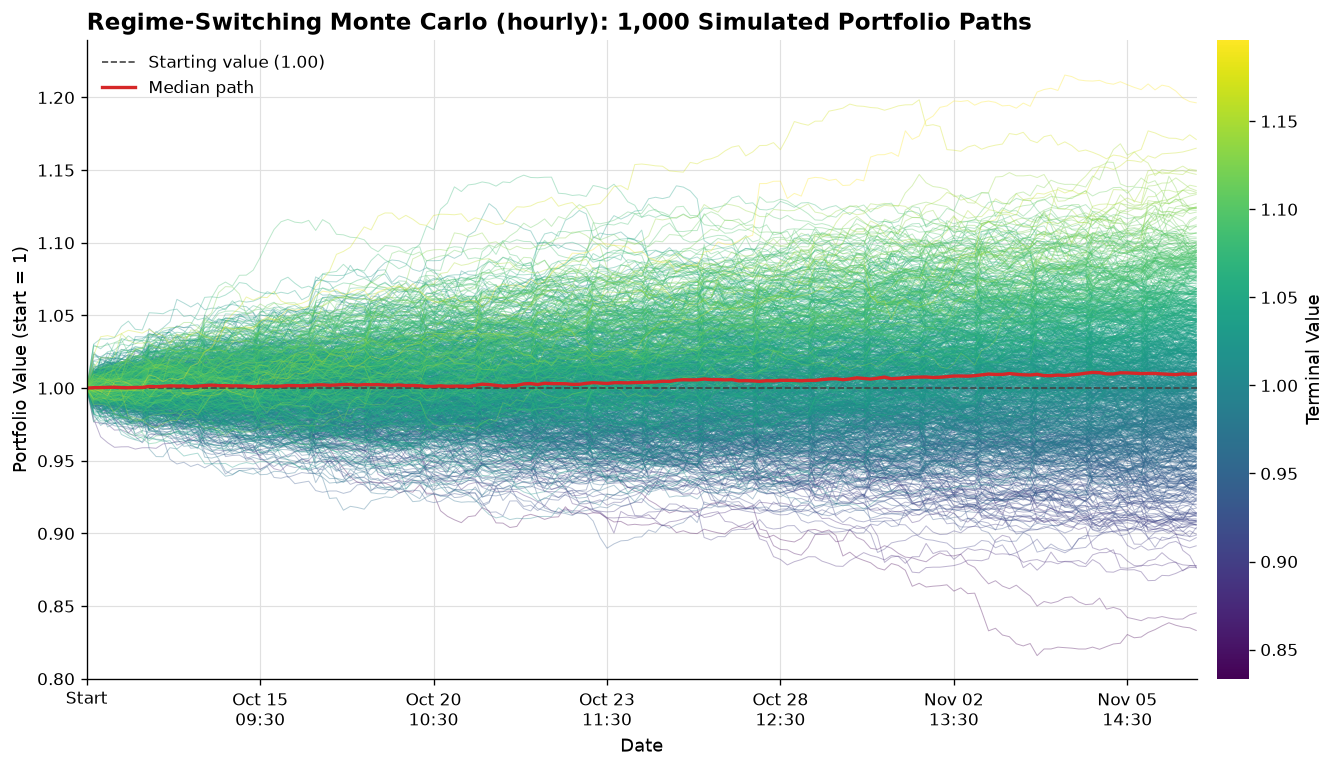

In [14]:
# Fan chart of the hourly paths; each column is one future mark
fig, ax = plot_simulated_paths(sims, method='Regime-Switching Monte Carlo (hourly)')
plt.show()

The statistical report computes its risk figures from each path's session returns. On a short horizon some paths may have no down session at all and an infinite Sortino ratio; the report warns with the count when that happens, which is why this forecast runs twenty sessions rather than a few. CAGR annualizes about a month, which magnifies it; Total Return is the figure to read. Gap and Bar Volatility are measured on the simulated gaps and bars, so compare them with the history's.

In [15]:
# Each figure's mean, median and 95% range across the paths
report = statistical_report(sims, display=True)


                     SIMULATED PORTFOLIO STATISTICAL REPORT                     
--------------------------------------------------------------------------------
  Simulated Paths      : 1,000
  Total Time           :  0.08 years (28 days)
  Horizon              :   160 periods
                                    RETURNS                                     
--------------------------------------------------------------------------------
                               Mean       Median         95% range across paths
--------------------------------------------------------------------------------
  Final Bankroll       :       1.01         1.01                   [0.91, 1.11]
  Total Return         :      1.12%        1.00%               [-8.80%, 10.71%]
  CAGR                 :     38.88%       13.31%             [-68.69%, 260.39%]
                                      RISK                                      
----------------------------------------------------------------------------

## **The Daily View: Session Closes**

For a daily forecast from intraday history, collapse it with [`to_session_values`](../README.md#to_session_values) ([input](../README.md#mc1-input)): the purchase, then each session's last value. Its returns are the session returns behind the risk figures, and on it `sim_length` counts sessions with one mark each. Yahoo Finance sometimes leaves out a session's final bars, such as a half-day's last bar; such a session's last value is labelled at its close, and a warning gives how many sessions it happened to. A year of session closes is about 250 daily returns, still a thin history for a daily forecast; the point is the shape of the result.

In [16]:
# The first value, then one value per session close
daily = to_session_values(backtest)
daily.tail()

/var/folders/4k/9t00rt713w3fsg126syp21gc0000gn/T/ipykernel_44870/2537109014.py:2: UserWarning: 3 session(s) end before their close, first 2025-11-28: each one's last value is labelled at its close
  daily = to_session_values(backtest)


2026-10-05 16:00:00-04:00    1.152107
2026-10-06 16:00:00-04:00    1.154080
2026-10-07 16:00:00-04:00    1.156984
2026-10-08 16:00:00-04:00    1.160933
2026-10-09 16:00:00-04:00    1.163652
dtype: float64

In [17]:
# The same twenty sessions forecast from session closes: one mark per session instead of eight
daily_sims = nonparametric_monte_carlo(daily, sim_length=20, n_sims=1000, random_state=np.random.default_rng(42))
pd.DataFrame({'Future marks': [sims.paths.shape[1] - 1, daily_sims.paths.shape[1] - 1],
              'Last mark': [sims.dates[-1], daily_sims.dates[-1]]},
             index=['Hourly history', 'Session closes'])

,Future marks,Last mark
Hourly history,160,2026-11-06 16:00:00-05:00
Session closes,20,2026-11-06 16:00:00-05:00


## **Continuous Mode for a 24/7 Asset**

Bitcoin trades around the clock, so it has no sessions, opens or gaps. `calendar=None` is continuous mode ([continuous mode](../README.md#u3-continuous-mode), [Calendars](../README.md#concepts)): the bars form a constant hourly grid, every return is regular (or irregular where a grid point is missing), and the future marks run every hour, weekends included. Risk figures use calendar-day returns at 00:00 UTC, annualized with 365, and CAGR needs the calendar clock, `cagr_clock='calendar'`.

In [18]:
# A year of hourly BTC-USD bars, backtested without a calendar
btc = yf.download('BTC-USD', period='1y', interval='1h', auto_adjust=True, progress=False)
btc_backtest = simulate_buy_and_hold(btc, {'BTC-USD': 1.0}, calendar=None)
btc_backtest.classes.value_counts()

/var/folders/4k/9t00rt713w3fsg126syp21gc0000gn/T/ipykernel_44870/979183419.py:3: UserWarning: 3 return(s) are irregular, first ending 2025-10-28 15:00:00+00:00: a held symbol is stale (no own price) at either end, or a scheduled bar is missing for every symbol. They stay in the values and metrics and are left out of Monte Carlo fits
  btc_backtest = simulate_buy_and_hold(btc, {'BTC-USD': 1.0}, calendar=None)


regular      8725
irregular       3
Name: count, dtype: int64

In [19]:
# The history's report on the calendar clock
btc_history = performance_report(btc_backtest, calendar=None, cagr_clock='calendar', display=True)


            PORTFOLIO PERFORMANCE REPORT            
----------------------------------------------------
  Total Time         :  1.00 years (365 days)
  Periods            :  8728 returns
                      RETURNS                       
----------------------------------------------------
  Initial Bankroll   :         1.00
  Final Bankroll     :         0.73
  Total Return       :      -27.21%
  CAGR               :      -27.23%
----------------------------------------------------
  Actual Yearly Returns:
    - 2025            :      -23.23%  (83 days)
    - 2026            :       -5.18%  (283 days)
                        RISK                        
----------------------------------------------------
  Volatility         :       44.56%
  Downside Vol       :       31.29%
  Bar Vol (per bar)  :        0.47%
  Max Drawdown       :       49.99%
  Sharpe Ratio       :        -0.49
  Sortino Ratio      :        -0.70



In continuous mode `sim_length` counts bars, so a week ahead is 168 hourly marks, all regular, with no step skipped over the weekend. The reports have no Gap Volatility row, since there are no gaps, and over a week CAGR is magnified out of all proportion: read Total Return.

In [20]:
# One week of hourly marks ahead; every future mark is a regular bar
btc_sims = nonparametric_monte_carlo(btc_backtest, sim_length=24 * 7, n_sims=1000, calendar=None,
                                     random_state=np.random.default_rng(42))
pd.Series(btc_sims.classes).value_counts()

regular    168
Name: count, dtype: int64

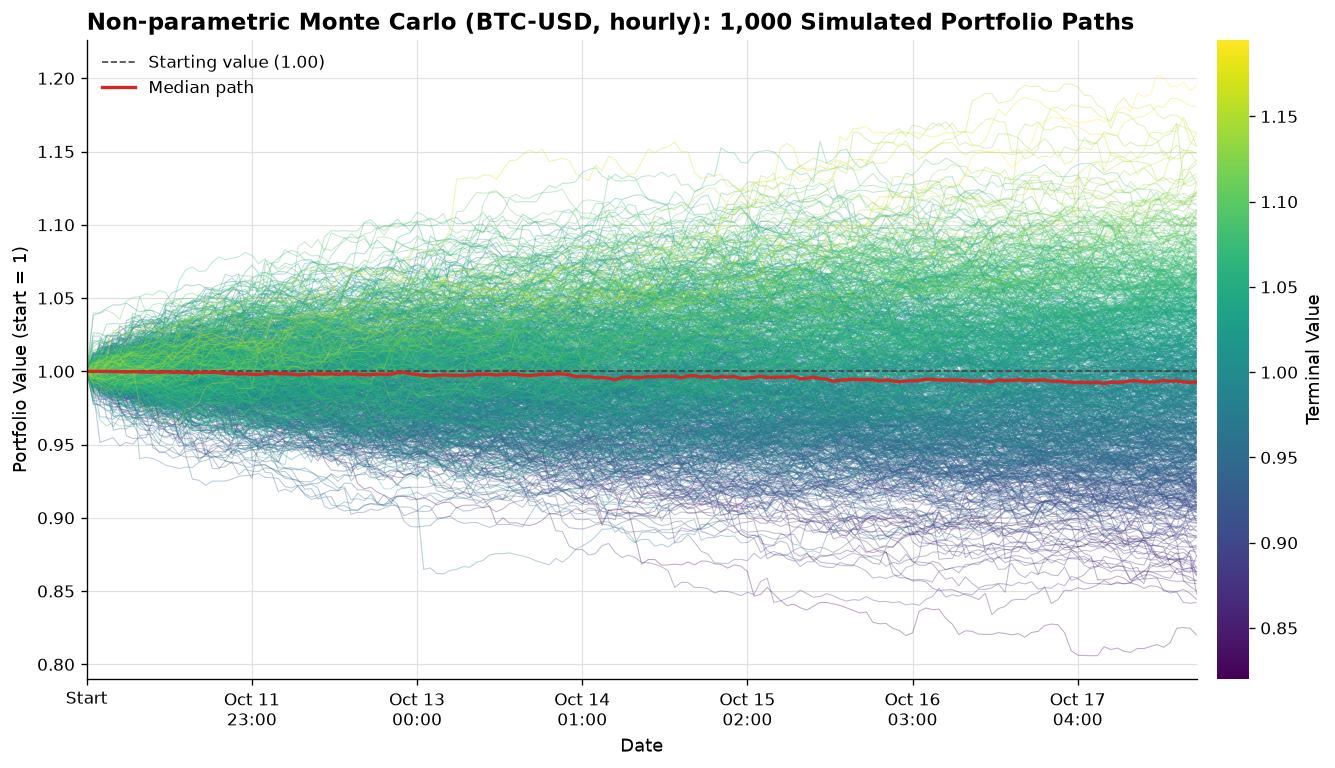


                     SIMULATED PORTFOLIO STATISTICAL REPORT                     
--------------------------------------------------------------------------------
  Simulated Paths      : 1,000
  Total Time           :  0.02 years (7 days)
  Horizon              :   168 periods
                                    RETURNS                                     
--------------------------------------------------------------------------------
                               Mean       Median         95% range across paths
--------------------------------------------------------------------------------
  Final Bankroll       :       0.99         0.99                   [0.89, 1.11]
  Total Return         :     -0.52%       -0.73%              [-11.32%, 11.07%]
  CAGR                 :   4636.30%      -31.65%           [-99.81%, 23900.40%]
                                      RISK                                      
-----------------------------------------------------------------------------

/var/folders/4k/9t00rt713w3fsg126syp21gc0000gn/T/ipykernel_44870/84634654.py:4: UserWarning: Sortino ratio is infinite on 13 of 1000 paths (1.3%); its mean is NaN
  btc_report = statistical_report(btc_sims, calendar=None, cagr_clock='calendar', display=True)


In [21]:
# The forecast's fan chart and report, on the calendar clock
fig, ax = plot_simulated_paths(btc_sims, method='Non-parametric Monte Carlo (BTC-USD, hourly)')
plt.show()
btc_report = statistical_report(btc_sims, calendar=None, cagr_clock='calendar', display=True)